<a href="https://colab.research.google.com/github/nilaynishant/acrs/blob/main/01_xarray_basics_for_satellite_image_visualisaton.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Overview

[`XArray`](https://docs.xarray.dev/en/stable/) has emerged as one of the key Python libraries to work with gridded raster datasets. It can natively handle time-series data making it ideal for working with Remote Sensing datasets. It builds on NumPy/Pandas for fast arrays/indexing and is orders of magnitude faster than other Python libraries like `rasterio`. It has a growing ecosystem of extensions `rioxarray`, `xarray-spatial`, `XEE` and more allowing it to be used for geospatial analysis. XArray offers the flexibility to seamlessly work with local datasets along with cloud-hosted datasets in a variety of optimized data formats.

In this section, we will learn about XArray basics and learn how to work with a time-series of Sentinel-2 satellite imagery to create and visualize a median composite image.

### Setup

Determine our runtime environment.

In [1]:
import os

if 'COLAB_RELEASE_TAG' in os.environ:
    environment = 'colab'
    if os.environ.get('VERTEX_PRODUCT') == 'COLAB_ENTERPRISE':
        environment = 'colab_enterprise'
else:
    environment = 'local'

print(f'Environment: {environment}')

Environment: colab


If we are on Google Colab, install the required packages. Local runtimes are expected to have the packages already installed.

In [2]:
%%capture
if environment in ['colab', 'colab_enterprise']:
      !pip install pystac-client odc-stac rioxarray dask['distributed'] botocore

Import all required libraries. Make sure to import everything at the beginning as certain Xarray extensions are activated on import and registers certain accesors, like `.rio` and `.odc` for Xarray objects.

In [3]:
import matplotlib.pyplot as plt
import os
import pystac_client
import rioxarray as rxr
import xarray as xr
from odc.stac import configure_s3_access, stac_load

### Get Satellite Imagery

We define a location in Delhi and a year of interest to fetch Sentinel-2 imagery.

In [4]:
latitude = 28.6139
longitude = 77.2090
year = 2023

Let's use Element84 search endpoint to look for items from the sentinel-2-l2a collection on AWS.

In [5]:
catalog = pystac_client.Client.open(
    'https://earth-search.aws.element84.com/v1')

# Configure settings for reading from Earth Search STAC
configure_s3_access(
    aws_unsigned=True,
)

# Define a small bounding box around the chosen point
km2deg = 1.0 / 111
x, y = (longitude, latitude)
r = 1 * km2deg  # radius in degrees
bbox = (x - r, y - r, x + r, y + r)

search = catalog.search(
    collections=['sentinel-2-c1-l2a'],
    bbox=bbox,
    datetime=f'{year}',
    query={'eo:cloud_cover': {'lt': 30}},
)
items = search.item_collection()

/usr/local/lib/python3.13/dist-packages/pystac/extensions/storage.py:724: UserWarning: Could not parse bucket/account from href. The following assets were not migrated: ['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail']
  warnings.warn(


Load the matching images as a XArray Dataset.

In [6]:
ds = stac_load(
    items,
    bands=['red', 'green', 'blue', 'nir'],
    resolution=10,
    crs='utm',
    bbox=bbox,
    chunks={},  # <-- use Dask
    groupby='solar_day',
)

In [7]:
%%time
ds = ds.compute()

CPU times: user 4.94 s, sys: 411 ms, total: 5.35 s
Wall time: 46.7 s


### XArray Terminology

We now have a `xarray.Dataset` object. Let's understand what is contained in a Dataset.

* *Variables*: This is similar to a band in a raster dataset. Each variable contains an array of values.
* *Dimensions*: This is similar to number of array axes.
* *Coordinates*: These are the labels for values in each dimension.
* *Attributes*: This is the metadata associated with the dataset.

<img src='https://courses.spatialthoughts.com/images/common/xarray_terminology.png' width=800/>

Let's see our `Dataset` and see what variables, coordinates and dimensions it contains.

In [8]:
ds

<xarray.Dataset> Size: 12MB
Dimensions:      (y: 203, x: 180, time: 41)
Coordinates:
  * y            (y) float64 2kB 3.168e+06 3.168e+06 ... 3.166e+06 3.166e+06
  * x            (x) float64 1kB 7.151e+05 7.151e+05 ... 7.169e+05 7.169e+05
  * time         (time) datetime64[ns] 328B 2023-01-19T05:40:58.356000 ... 20...
    spatial_ref  int32 4B 32643
Data variables:
    red          (time, y, x) uint16 3MB 1791 1460 1354 1440 ... 1308 1380 1376
    green        (time, y, x) uint16 3MB 1714 1425 1356 1471 ... 1398 1552 1447
    blue         (time, y, x) uint16 3MB 1548 1227 1214 1265 ... 1195 1324 1354
    nir          (time, y, x) uint16 3MB 2086 1680 1942 2339 ... 2956 2994 2472

A Dataset consists of one or more `xarray.DataArray` object. This is the main object that consists of a single variable with dimension names, coordinates and attributes. You can access each variable using `dataset[variable_name]` or `dataset.varaible_name` syntax.

In [9]:
da = ds['red']
da

<xarray.DataArray 'red' (time: 41, y: 203, x: 180)> Size: 3MB
array([[[1791, 1460, 1354, ..., 1514, 1758, 1973],
        [1844, 1493, 1373, ..., 1469, 1474, 1718],
        [1860, 1508, 1350, ..., 1447, 1447, 1987],
        ...,
        [1491, 1400, 1322, ..., 1446, 1516, 1495],
        [1302, 1311, 1355, ..., 1478, 1538, 1530],
        [1399, 1391, 1477, ..., 1444, 1574, 1548]],

       [[1988, 1404, 1334, ..., 1526, 1838, 2160],
        [2020, 1480, 1340, ..., 1530, 1584, 1821],
        [2064, 1568, 1317, ..., 1378, 1446, 2108],
        ...,
        [1462, 1311, 1300, ..., 1246, 1408, 1331],
        [1302, 1268, 1273, ..., 1290, 1336, 1394],
        [1298, 1346, 1500, ..., 1288, 1330, 1360]],

       [[2060, 1538, 1413, ..., 1606, 1902, 2164],
        [2034, 1568, 1420, ..., 1564, 1614, 1797],
        [2124, 1712, 1451, ..., 1502, 1586, 1970],
        ...,
...
        ...,
        [1425, 1436, 1490, ..., 1394, 1502, 1474],
        [1420, 1334, 1296, ..., 1388, 1470, 1462],
        [1376, 1329, 1357, ..., 1418, 1492, 1477]],

       [[2976, 2814, 2836, ..., 2722, 2864, 3102],
        [2908, 2782, 2768, ..., 2670, 2758, 3000],
        [2946, 2850, 2722, ..., 2618, 2650, 3038],
        ...,
        [2110, 2066, 2042, ..., 2188, 2264, 2306],
        [2082, 2088, 2084, ..., 2178, 2278, 2316],
        [2120, 2150, 2278, ..., 2184, 2224, 2238]],

       [[1752, 1334, 1312, ..., 1535, 1700, 2074],
        [1653, 1364, 1286, ..., 1538, 1594, 2138],
        [1961, 1550, 1322, ..., 1564, 1596, 2252],
        ...,
        [1333, 1291, 1243, ..., 1329, 1438, 1373],
        [1304, 1268, 1267, ..., 1348, 1381, 1384],
        [1334, 1382, 1536, ..., 1308, 1380, 1376]]], dtype=uint16)
Coordinates:
  * time         (time) datetime64[ns] 328B 2023-01-19T05:40:58.356000 ... 20...
  * y            (y) float64 2kB 3.168e+06 3.168e+06 ... 3.166e+06 3.166e+06
  * x            (x) float64 1kB 7.151e+05 7.151e+05 ... 7.169e+05 7.169e+05
    spatial_ref  int32 4B 32643
Attributes:
    nodata:   0

### Selecting Data

XArray provides a very powerful way to select subsets of data, using similar framework as Pandas. Similar to Panda's `loc` and `iloc` methods, XArray provides `sel` and `isel` methods. Since DataArray dimensions have names, these methods allow you to specify which dimension to query.

Let's select the image for the last time step. Since we know the index (-1) of the data we can use `isel` method.

In [10]:
da.isel(time=-1)

<xarray.DataArray 'red' (y: 203, x: 180)> Size: 73kB
array([[1752, 1334, 1312, ..., 1535, 1700, 2074],
       [1653, 1364, 1286, ..., 1538, 1594, 2138],
       [1961, 1550, 1322, ..., 1564, 1596, 2252],
       ...,
       [1333, 1291, 1243, ..., 1329, 1438, 1373],
       [1304, 1268, 1267, ..., 1348, 1381, 1384],
       [1334, 1382, 1536, ..., 1308, 1380, 1376]], dtype=uint16)
Coordinates:
  * y            (y) float64 2kB 3.168e+06 3.168e+06 ... 3.166e+06 3.166e+06
  * x            (x) float64 1kB 7.151e+05 7.151e+05 ... 7.169e+05 7.169e+05
    spatial_ref  int32 4B 32643
    time         datetime64[ns] 8B 2023-12-25T05:41:00.350000
Attributes:
    nodata:   0

You can call `.values` on a DataArray to get an array of the values.

In [11]:
da.isel(time=-1).values

array([[1752, 1334, 1312, ..., 1535, 1700, 2074],
       [1653, 1364, 1286, ..., 1538, 1594, 2138],
       [1961, 1550, 1322, ..., 1564, 1596, 2252],
       ...,
       [1333, 1291, 1243, ..., 1329, 1438, 1373],
       [1304, 1268, 1267, ..., 1348, 1381, 1384],
       [1334, 1382, 1536, ..., 1308, 1380, 1376]], dtype=uint16)

You can query for a values at using multiple dimensions.

In [12]:
da.isel(time=-1, x=-1, y=-1).values

array(1376, dtype=uint16)

You can use `.item()` on any output to get the standard Python scalar object.

In [13]:
da.isel(time=-1, x=-1, y=-1).values.item()

1376

We can also specify a value to query using the `sel()` method.

Let's see what are the values of `time` variable.

In [14]:
dates = da.time.values
dates

array(['2023-01-19T05:40:58.356000000', '2023-02-03T05:41:00.397000000',
       '2023-02-08T05:41:02.428000000', '2023-02-13T05:41:02.035000000',
       '2023-02-18T05:41:00.348000000', '2023-02-23T05:41:03.627000000',
       '2023-03-05T05:41:06.005000000', '2023-03-10T05:40:58.438000000',
       '2023-03-15T05:41:07.755000000', '2023-03-25T05:41:06.051000000',
       '2023-03-30T05:41:01.472000000', '2023-04-04T05:41:06.759000000',
       '2023-04-09T05:41:03.650000000', '2023-04-14T05:41:04.143000000',
       '2023-04-19T05:41:02.339000000', '2023-05-04T05:41:06.067000000',
       '2023-05-09T05:41:03.201000000', '2023-05-14T05:41:07.045000000',
       '2023-05-19T05:41:05.614000000', '2023-05-29T05:41:07.274000000',
       '2023-06-03T05:41:07.535000000', '2023-06-08T05:41:07.079000000',
       '2023-06-13T05:41:08.579000000', '2023-08-12T05:41:09.123000000',
       '2023-08-17T05:41:09.390000000', '2023-08-27T05:41:09.373000000',
       '2023-09-01T05:41:08.301000000', '2023-09-21

We can query using the value of a coordinate using the `sel()` method.

In [16]:
da.sel(time='2023-05-29T05:41:07.274000000')

<xarray.DataArray 'red' (y: 203, x: 180)> Size: 73kB
array([[2104, 1770, 1407, ..., 1537, 1903, 2653],
       [1973, 1734, 1410, ..., 1557, 1651, 2414],
       [2046, 1749, 1457, ..., 1870, 1966, 2610],
       ...,
       [1733, 1796, 1747, ..., 1478, 1646, 1642],
       [1713, 1633, 1443, ..., 1405, 1527, 1656],
       [1485, 1503, 1528, ..., 1340, 1493, 1686]], dtype=uint16)
Coordinates:
  * y            (y) float64 2kB 3.168e+06 3.168e+06 ... 3.166e+06 3.166e+06
  * x            (x) float64 1kB 7.151e+05 7.151e+05 ... 7.169e+05 7.169e+05
    spatial_ref  int32 4B 32643
    time         datetime64[ns] 8B 2023-05-29T05:41:07.274000
Attributes:
    nodata:   0

The `sel()` method also support nearest neighbor lookups. This is useful when you do not know the exact label of the dimension, but want to find the closest one.

> Tip: You can use `interp()` instead of `sel()` to interpolate the value instead of closest lookup.

In [17]:
da.sel(time='2023-01-01', method='nearest')

<xarray.DataArray 'red' (y: 203, x: 180)> Size: 73kB
array([[1791, 1460, 1354, ..., 1514, 1758, 1973],
       [1844, 1493, 1373, ..., 1469, 1474, 1718],
       [1860, 1508, 1350, ..., 1447, 1447, 1987],
       ...,
       [1491, 1400, 1322, ..., 1446, 1516, 1495],
       [1302, 1311, 1355, ..., 1478, 1538, 1530],
       [1399, 1391, 1477, ..., 1444, 1574, 1548]], dtype=uint16)
Coordinates:
  * y            (y) float64 2kB 3.168e+06 3.168e+06 ... 3.166e+06 3.166e+06
  * x            (x) float64 1kB 7.151e+05 7.151e+05 ... 7.169e+05 7.169e+05
    spatial_ref  int32 4B 32643
    time         datetime64[ns] 8B 2023-01-19T05:40:58.356000
Attributes:
    nodata:   0

We can query using partial data strings for broad matches as well.

In [18]:
da.sel(time='2023-01')

<xarray.DataArray 'red' (time: 1, y: 203, x: 180)> Size: 73kB
array([[[1791, 1460, 1354, ..., 1514, 1758, 1973],
        [1844, 1493, 1373, ..., 1469, 1474, 1718],
        [1860, 1508, 1350, ..., 1447, 1447, 1987],
        ...,
        [1491, 1400, 1322, ..., 1446, 1516, 1495],
        [1302, 1311, 1355, ..., 1478, 1538, 1530],
        [1399, 1391, 1477, ..., 1444, 1574, 1548]]], dtype=uint16)
Coordinates:
  * time         (time) datetime64[ns] 8B 2023-01-19T05:40:58.356000
  * y            (y) float64 2kB 3.168e+06 3.168e+06 ... 3.166e+06 3.166e+06
  * x            (x) float64 1kB 7.151e+05 7.151e+05 ... 7.169e+05 7.169e+05
    spatial_ref  int32 4B 32643
Attributes:
    nodata:   0

The `sel()` method also allows specifying range of values using Python's built-in `slice()` function. The code below will select all observations during January 2023.

In [19]:
da.sel(time=slice('2023-01-01', '2023-01-31'))

<xarray.DataArray 'red' (time: 1, y: 203, x: 180)> Size: 73kB
array([[[1791, 1460, 1354, ..., 1514, 1758, 1973],
        [1844, 1493, 1373, ..., 1469, 1474, 1718],
        [1860, 1508, 1350, ..., 1447, 1447, 1987],
        ...,
        [1491, 1400, 1322, ..., 1446, 1516, 1495],
        [1302, 1311, 1355, ..., 1478, 1538, 1530],
        [1399, 1391, 1477, ..., 1444, 1574, 1548]]], dtype=uint16)
Coordinates:
  * time         (time) datetime64[ns] 8B 2023-01-19T05:40:58.356000
  * y            (y) float64 2kB 3.168e+06 3.168e+06 ... 3.166e+06 3.166e+06
  * x            (x) float64 1kB 7.151e+05 7.151e+05 ... 7.169e+05 7.169e+05
    spatial_ref  int32 4B 32643
Attributes:
    nodata:   0

### Exercise 1: Selecting Data

Practice the selection techniques above using the `da` (red band) DataArray.

1. How many Sentinel-2 scenes were acquired in **November 2023**? *(Hint: `da.sel(time='2023-11').time.size`)*
2. Select the scene whose acquisition date is closest to **`2023-06-15`** and print its exact timestamp.
3. Select all scenes acquired between **1 May and 31 May 2023** using `slice()` and count them.

In [ ]:
# 1. Count scenes in November 2023
nov = da.sel(time='2023-11')
print('Scenes in November 2023:', nov.time.size)

# 2. Scene closest to 2023-06-15
june_scene = da.sel(time='2023-06-15', method='nearest')
print('Nearest scene to 2023-06-15:', june_scene.time.values)

# 3. Scenes in May 2023
may_scenes = da.sel(time=slice('2023-05-01', '2023-05-31'))
print('Scenes in May 2023:', may_scenes.time.size)

### Aggregating Data

A very-powerful feature of XArray is the ability to easily aggregate data across dimensions - making it ideal for many remote sensing analysis. Let's create a median composite from all the individual images.

We apply the `.median()` aggregation across the `time` dimension.

In [20]:
median = ds.median(dim='time')
median

<xarray.Dataset> Size: 1MB
Dimensions:      (y: 203, x: 180)
Coordinates:
  * y            (y) float64 2kB 3.168e+06 3.168e+06 ... 3.166e+06 3.166e+06
  * x            (x) float64 1kB 7.151e+05 7.151e+05 ... 7.169e+05 7.169e+05
    spatial_ref  int32 4B 32643
Data variables:
    red          (y, x) float64 292kB 2.104e+03 1.708e+03 ... 1.542e+03 1.64e+03
    green        (y, x) float64 292kB 2.01e+03 1.694e+03 ... 1.651e+03 1.704e+03
    blue         (y, x) float64 292kB 1.818e+03 1.538e+03 ... 1.488e+03
    nir          (y, x) float64 292kB 2.676e+03 2.539e+03 ... 3.427e+03 3.03e+03

### Exercise 2: Compute NDVI

The **Normalized Difference Vegetation Index (NDVI)** highlights vegetation using the contrast between reflected NIR and absorbed Red light.

**Formula:** `NDVI = (NIR − Red) / (NIR + Red)`

Values range from −1 to +1. Above ~0.3 = vegetation; below 0.2 = built-up / bare soil.

Using the `median` composite:
1. Compute NDVI from `median['nir']` and `median['red']`.
2. Print the minimum and maximum NDVI values across the scene.
3. Plot NDVI using the `'RdYlGn'` colormap. Where is vegetation concentrated in Delhi?

In [ ]:
ndvi = (median['nir'] - median['red']) / (median['nir'] + median['red'])
ndvi.name = 'NDVI'

print(f'NDVI min: {float(ndvi.min()):.3f}')
print(f'NDVI max: {float(ndvi.max()):.3f}')

fig, ax = plt.subplots(1, 1)
fig.set_size_inches(5, 5)
ndvi.plot.imshow(ax=ax, cmap='RdYlGn', vmin=0.0, vmax=0.5)
ax.set_title('NDVI – Delhi 2023')
ax.set_axis_off()
ax.set_aspect('equal')
plt.show()

### Visualizing Data

XArray provides a `plot.imshow()` method based on Matplotlib to plot DataArrays.

Reference : [xarray.plot.imshow ](https://docs.xarray.dev/en/stable/generated/xarray.plot.imshow.html)

To visualize our Dataset, we first convert it to a DataArray using the `to_array()` method. All the variables will be converted to a new dimension. Since our variables are image bands, we give the name of the new dimesion as `band`.

In [21]:
median_da = median.to_array('band')
median_da

<xarray.DataArray (band: 4, y: 203, x: 180)> Size: 1MB
array([[[2104., 1708., 1415., ..., 1598., 1996., 2530.],
        [1930., 1664., 1438., ..., 1606., 1704., 2192.],
        [1972., 1712., 1482., ..., 1694., 1759., 2404.],
        ...,
        [1632., 1636., 1582., ..., 1446., 1562., 1544.],
        [1570., 1548., 1448., ..., 1422., 1527., 1607.],
        [1492., 1503., 1548., ..., 1413., 1542., 1640.]],

       [[2010., 1694., 1550., ..., 1778., 2020., 2460.],
        [1906., 1680., 1562., ..., 1818., 1808., 2062.],
        [1972., 1713., 1543., ..., 1812., 1853., 2358.],
        ...,
        [1756., 1714., 1662., ..., 1556., 1667., 1634.],
        [1651., 1700., 1571., ..., 1566., 1622., 1673.],
        [1654., 1704., 1763., ..., 1538., 1651., 1704.]],

       [[1818., 1538., 1382., ..., 1495., 1750., 2224.],
        [1718., 1496., 1380., ..., 1518., 1502., 1899.],
        [1758., 1566., 1370., ..., 1575., 1552., 2082.],
        ...,
        [1485., 1470., 1459., ..., 1379., 1472., 1457.],
        [1442., 1420., 1376., ..., 1381., 1438., 1468.],
        [1404., 1398., 1431., ..., 1357., 1401., 1488.]],

       [[2676., 2539., 3233., ..., 3866., 3632., 3292.],
        [2954., 2714., 3352., ..., 3971., 3676., 3167.],
        [3152., 2585., 3200., ..., 3260., 3426., 3233.],
        ...,
        [3220., 2882., 2873., ..., 3098., 3136., 2812.],
        [2833., 2946., 3450., ..., 3264., 3264., 3142.],
        [3246., 3652., 3758., ..., 3335., 3427., 3030.]]])
Coordinates:
  * band         (band) object 32B 'red' 'green' 'blue' 'nir'
  * y            (y) float64 2kB 3.168e+06 3.168e+06 ... 3.166e+06 3.166e+06
  * x            (x) float64 1kB 7.151e+05 7.151e+05 ... 7.169e+05 7.169e+05
    spatial_ref  int32 4B 32643

The easy way to visualize the data without the outliers is to pass the parameter `robust=True`. This will use the 2nd and 98th percentiles of the data to compute the color limits. We also specify the `set_aspect('equal')` to ensure the original aspect ratio is maintained and the image is not stretched.

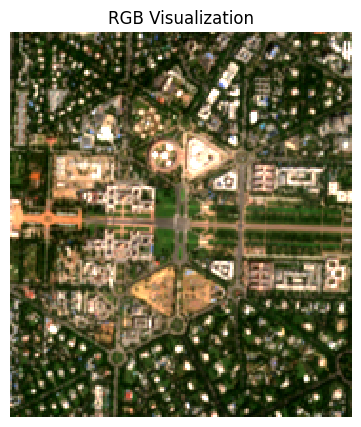

In [22]:
fig, ax = plt.subplots(1, 1)
fig.set_size_inches(5,5)
median_da.sel(band=['red', 'green', 'blue']).plot.imshow(
    ax=ax,
    robust=True)
ax.set_title('RGB Visualization')
ax.set_axis_off()
ax.set_aspect('equal')
plt.show()

### Exercise 3: Monthly Composite

Display the median composite for the month of May.

The snippet below takes our time-series and aggregate it to a monthly median composites `groupby()` method.

In [23]:
monthly = ds.groupby('time.month').median(dim='time')
monthly

<xarray.Dataset> Size: 13MB
Dimensions:      (month: 11, y: 203, x: 180)
Coordinates:
  * month        (month) int64 88B 1 2 3 4 5 6 8 9 10 11 12
  * y            (y) float64 2kB 3.168e+06 3.168e+06 ... 3.166e+06 3.166e+06
  * x            (x) float64 1kB 7.151e+05 7.151e+05 ... 7.169e+05 7.169e+05
    spatial_ref  int32 4B 32643
Data variables:
    red          (month, y, x) float64 3MB 1.791e+03 1.46e+03 ... 1.462e+03
    green        (month, y, x) float64 3MB 1.714e+03 1.425e+03 ... 1.549e+03
    blue         (month, y, x) float64 3MB 1.548e+03 1.227e+03 ... 1.443e+03
    nir          (month, y, x) float64 3MB 2.086e+03 1.68e+03 ... 2.8e+03

The code below displays an RGB composite for every available month as subplots. Note that July is absent — Delhi's monsoon makes those scenes too cloudy to pass the cloud-cover filter.

In [ ]:
monthly_da = monthly.to_array('band')

month_names = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
               7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}
months_available = monthly.month.values

ncols = 4
nrows = -(-len(months_available) // ncols)  # ceiling division

fig, axes = plt.subplots(nrows, ncols)
fig.set_size_inches(16, nrows * 4)

for i, month in enumerate(months_available):
    ax = axes.flat[i]
    monthly_da.sel(band=['red', 'green', 'blue'], month=month).plot.imshow(
        ax=ax, robust=True)
    ax.set_title(month_names[month])
    ax.set_axis_off()
    ax.set_aspect('equal')

for j in range(len(months_available), nrows * ncols):
    axes.flat[j].set_visible(False)

plt.suptitle('Monthly RGB Composites – Delhi 2023', fontsize=14)
plt.tight_layout()
plt.show()

### Exercise 4: Seasonal Comparison

Delhi has distinct seasons — **May** is hot and dry (pre-monsoon), while **October** is lush green after the monsoon rains. Both months are available in the `monthly` dataset.

1. Convert `monthly` to a DataArray with `to_array('band')`.
2. Plot the RGB composite for **May** (month 5) and **October** (month 10) side by side using `plt.subplots(1, 2)`.
3. Look at the images — can you see the difference in vegetation and dust haze?

In [ ]:
monthly_da = monthly.to_array('band')

fig, axes = plt.subplots(1, 2)
fig.set_size_inches(10, 5)

for ax, month, label in zip(axes, [5, 10], ['May (Pre-Monsoon)', 'October (Post-Monsoon)']):
    monthly_da.sel(band=['red', 'green', 'blue'], month=month).plot.imshow(
        ax=ax, robust=True)
    ax.set_title(label)
    ax.set_axis_off()
    ax.set_aspect('equal')

plt.tight_layout()
plt.show()

### Exercise 5: Pixel Time Series

One of XArray's strengths is extracting a time series at a specific location — very useful for monitoring vegetation or land-cover change through the year.

1. Compute NDVI for the **full time-series** `ds` (not just the median) using the formula from Exercise 2.
2. Extract the value at the **central pixel** using `isel(x=..., y=...)`.
3. Plot NDVI against time. Can you spot the monsoon greening in July–September?

In [ ]:
# Compute NDVI for every time step
ndvi_ts = (ds['nir'] - ds['red']) / (ds['nir'] + ds['red'])

# Extract the central pixel
cx = len(ndvi_ts.x) // 2
cy = len(ndvi_ts.y) // 2
ndvi_pixel = ndvi_ts.isel(x=cx, y=cy)

fig, ax = plt.subplots(1, 1)
fig.set_size_inches(10, 4)
ndvi_pixel.plot(ax=ax, marker='o', linestyle='-', color='green')
ax.set_title('NDVI Time Series – Delhi 2023 (Central Pixel)')
ax.set_xlabel('Date')
ax.set_ylabel('NDVI')
ax.grid(True, alpha=0.3)
plt.show()